In [1]:
# Global Imports and Visual Settings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OrdinalEncoder, TargetEncoder, LabelEncoder

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 4)

print("Libraries for Ordinal, Label, Frequency, and Target Encoding loaded successfully.")

Libraries for Ordinal, Label, Frequency, and Target Encoding loaded successfully.


# Table of Contents
- 1. What is Ordinal Encoding? (Preserving Natural Hierarchy)
- 2. Simple Example: Education Levels (Pandas Mapping)
- 3. Production Pipeline with Scikit-Learn (`OrdinalEncoder`)
- 4. What is Label Encoding? (`LabelEncoder` for Target $y$ vs Features $X$)
- 5. What is Frequency (Count) Encoding? (Handling High Cardinality)
- 6. Simple Example: Customer Cities (Frequency Normalization)
- 7. What is Target (Mean) Encoding? (Direct Target Correlation)
- 8. Hands-on Target Encoding: Naive vs Smoothed (M-Estimate) vs Scikit-Learn `TargetEncoder`
- 9. Visualizing Category Comparisons: Frequency vs Target Encoding vs Global Baseline
- 10. Summary Comparison Matrix: One-Hot vs Ordinal vs Label vs Frequency vs Target Encoding
- 11. 🎯 Critical Interview Traps, Viva Hacks & Things to Learn

## 1. What is Ordinal Encoding? (Preserving Natural Hierarchy)

**Ordinal Data** refers to categorical variables that possess a meaningful, natural ranking or order:
$$\text{Low} < \text{Medium} < \text{High}$$
$$\text{High School} < \text{Bachelor's} < \text{Master's} < \text{PhD}$$
$$\text{Bronze} < \text{Silver} < \text{Gold} < \text{Platinum}$$

In **Ordinal Encoding**, each category is converted into an integer reflecting its exact position in the hierarchy:
$$\text{Mapping: } c_i \mapsto i, \quad \text{where } c_1 < c_2 < \dots < c_K$$

### Why Not One-Hot Encoding for Ordinal Data?
- One-Hot Encoding treats all categories as equidistant and independent, **discarding the valuable order information** ($1 < 2 < 3$).
- Ordinal Encoding preserves this progression while adding only **1 single column**, keeping memory low.

In [2]:
# 2. Simple Example: Employee Education Level
df_employee = pd.DataFrame({
    'employee_id': [101, 102, 103, 104, 105, 106],
    'education': ['High School', 'Bachelor', 'Master', 'PhD', 'Bachelor', 'High School'],
    'experience_years': [2, 4, 7, 10, 5, 1],
    'salary': [35000, 55000, 85000, 115000, 62000, 32000]
})

print("Original Employee Dataset:")
print(df_employee)
print("_" * 60)

# Define explicit natural ordering
education_hierarchy = {
    'High School': 1,
    'Bachelor': 2,
    'Master': 3,
    'PhD': 4
}

# Apply explicit dictionary mapping
df_employee['education_encoded'] = df_employee['education'].map(education_hierarchy)

print("Ordinal Encoded Dataset (Order: High School=1 < Bachelor=2 < Master=3 < PhD=4):")
print(df_employee[['employee_id', 'education', 'education_encoded', 'salary']])

Original Employee Dataset:
   employee_id    education  experience_years  salary
0          101  High School                 2   35000
1          102     Bachelor                 4   55000
2          103       Master                 7   85000
3          104          PhD                10  115000
4          105     Bachelor                 5   62000
5          106  High School                 1   32000
____________________________________________________________
Ordinal Encoded Dataset (Order: High School=1 < Bachelor=2 < Master=3 < PhD=4):
   employee_id    education  education_encoded  salary
0          101  High School                  1   35000
1          102     Bachelor                  2   55000
2          103       Master                  3   85000
3          104          PhD                  4  115000
4          105     Bachelor                  2   62000
5          106  High School                  1   32000


## 3. Production Pipeline with Scikit-Learn (`OrdinalEncoder`)

In machine learning pipelines, we use Scikit-Learn's `OrdinalEncoder`. 

> ⚠️ **CRITICAL WARNING:** By default, `OrdinalEncoder()` orders categories **alphabetically** (`'Bachelor' -> 0`, `'High School' -> 1`, `'Master' -> 2`, `'PhD' -> 3`). That would wrongly make Bachelor's lower than High School!  
> **Always pass explicit ordered categories:** `categories=[['High School', 'Bachelor', 'Master', 'PhD']]`.

In [3]:
# Explicit Scikit-Learn OrdinalEncoder
ordered_categories = [['High School', 'Bachelor', 'Master', 'PhD']]

encoder = OrdinalEncoder(categories=ordered_categories)
df_employee['sklearn_encoded'] = encoder.fit_transform(df_employee[['education']])

print("Scikit-Learn Explicit Ordinal Encoding:")
print(df_employee[['education', 'education_encoded', 'sklearn_encoded']])
print("_" * 60)
print("Encoder Categories List:", encoder.categories_)

Scikit-Learn Explicit Ordinal Encoding:
     education  education_encoded  sklearn_encoded
0  High School                  1              0.0
1     Bachelor                  2              1.0
2       Master                  3              2.0
3          PhD                  4              3.0
4     Bachelor                  2              1.0
5  High School                  1              0.0
____________________________________________________________
Encoder Categories List: [array(['High School', 'Bachelor', 'Master', 'PhD'], dtype=object)]


## 4. What is Label Encoding? (`LabelEncoder` for Target $y$ vs Features $X$)

`LabelEncoder` converts text labels into numbers: $0, 1, 2, \dots, K-1$.

> 🛑 **CRITICAL INTERVIEW LAW:**  
> - Use `LabelEncoder` **EXCLUSIVELY for the Target Variable ($y$)** in classification tasks!  
> - **DO NOT USE `LabelEncoder` on input feature columns ($X$)!**

### Why is `LabelEncoder` wrong for input features $X$?
1. **Arbitrary Alphabetical Assignment:** It maps categories alphabetically, creating false rank orders with no logical hierarchy.
2. **Biases Linear & Distance Models:** A regression model or neural net interprets integer `2` as twice as large as `1` ($1 < 2 < 3$).
3. **Pipeline Incompatibility:** `LabelEncoder` expects a 1D vector `(n_samples,)`, not a 2D matrix `(n_samples, n_features)`. It cannot be used inside `ColumnTransformer`. For input features, always use `OrdinalEncoder`!

In [4]:
# 4. Correct Use of LabelEncoder on Target Variable (y)
# Predicting customer loan approval: ['Denied', 'Approved', 'Pending']
df_loan = pd.DataFrame({
    'applicant_id': [501, 502, 503, 504, 505],
    'credit_score': [720, 580, 810, 640, 750],
    'loan_status': ['Approved', 'Denied', 'Approved', 'Pending', 'Approved']
})

print("Original Loan Application Data:")
print(df_loan)
print("-" * 50)

# Apply LabelEncoder to Target y (1D series)
label_enc = LabelEncoder()
df_loan['loan_status_encoded'] = label_enc.fit_transform(df_loan['loan_status'])

print("Target Encoded with LabelEncoder:")
print(df_loan[['applicant_id', 'credit_score', 'loan_status', 'loan_status_encoded']])
print("-" * 50)
print("Encoded Classes:", label_enc.classes_)
print("Reversible Mapping: 0 ->", label_enc.inverse_transform([0])[0], 
      ", 1 ->", label_enc.inverse_transform([1])[0], 
      ", 2 ->", label_enc.inverse_transform([2])[0])

Original Loan Application Data:
   applicant_id  credit_score loan_status
0           501           720    Approved
1           502           580      Denied
2           503           810    Approved
3           504           640     Pending
4           505           750    Approved
--------------------------------------------------
Target Encoded with LabelEncoder:
   applicant_id  credit_score loan_status  loan_status_encoded
0           501           720    Approved                    0
1           502           580      Denied                    1
2           503           810    Approved                    0
3           504           640     Pending                    2
4           505           750    Approved                    0
--------------------------------------------------
Encoded Classes: ['Approved' 'Denied' 'Pending']
Reversible Mapping: 0 -> Approved , 1 -> Denied , 2 -> Pending


## 5. What is Frequency (Count) Encoding? (Handling High Cardinality)

### The Problem: High Cardinality Nominal Data
Suppose a dataset has a feature like `city`, `zip_code`, or `product_brand` with hundreds or thousands of categories:
- One-Hot Encoding would create 500+ sparse columns, causing the **Curse of Dimensionality** and memory exhaustion.
- Ordinal Encoding is invalid because cities (`Mumbai`, `Delhi`, `Pune`) have no natural mathematical hierarchy (`Mumbai < Delhi` is meaningless).

---

### The Solution: Frequency (Count) Encoding
**Frequency Encoding** replaces each category with its percentage frequency (or count) in the dataset:

$$\text{Frequency}(C) = \frac{\text{Count}(C)}{N}$$

- Frequently occurring categories receive **higher values**.
- Rare categories receive **lower values** near 0.
- Adds only **1 single numeric column**, solving the curse of dimensionality!

In [5]:
# 6. Simple Example: Customer Orders by City
np.random.seed(42)

df_customers = pd.DataFrame({
    'order_id': range(1001, 1011),
    'city': ['Mumbai', 'Delhi', 'Mumbai', 'Bengaluru', 'Mumbai', 'Delhi', 'Pune', 'Mumbai', 'Bengaluru', 'Delhi'],
    'order_amount': [120, 85, 230, 45, 310, 150, 95, 180, 210, 115]
})

print("Original Customer Orders:")
print(df_customers.head(5))
print("_" * 60)

# Calculate Normalized Frequencies (Proportion of total rows)
city_frequency_map = df_customers['city'].value_counts(normalize=True).round(3)
print("Frequency Distribution Map (Normalized):")
print(city_frequency_map)
print("_" * 60)

# Map frequency back into DataFrame
df_customers['city_frequency'] = df_customers['city'].map(city_frequency_map)

print("Dataset with Frequency Encoding:")
print(df_customers[['order_id', 'city', 'city_frequency', 'order_amount']])

Original Customer Orders:
   order_id       city  order_amount
0      1001     Mumbai           120
1      1002      Delhi            85
2      1003     Mumbai           230
3      1004  Bengaluru            45
4      1005     Mumbai           310
____________________________________________________________
Frequency Distribution Map (Normalized):
city
Mumbai       0.4
Delhi        0.3
Bengaluru    0.2
Pune         0.1
Name: proportion, dtype: float64
____________________________________________________________
Dataset with Frequency Encoding:
   order_id       city  city_frequency  order_amount
0      1001     Mumbai             0.4           120
1      1002      Delhi             0.3            85
2      1003     Mumbai             0.4           230
3      1004  Bengaluru             0.2            45
4      1005     Mumbai             0.4           310
5      1006      Delhi             0.3           150
6      1007       Pune             0.1            95
7      1008     Mumbai    

## 7. What is Target (Mean) Encoding? (Direct Target Correlation)

### Why Frequency Encoding Isn't Always Enough
While Frequency Encoding captures category popularity, it completely ignores the **target variable ($Y$)**:
- A small boutique city (`Pune`) may only have 1 order, giving it a tiny frequency of `0.10`.
- But what if orders from Pune average **$500+**? Frequency encoding treats Pune as unimportant, discarding its high purchasing power!

---

### The Solution: Target Encoding (Mean Encoding)
**Target Encoding** replaces each category with the average value of the target variable $Y$ for that category:

$$\hat{x}_c = E[Y \mid X = c] = \frac{1}{n_c} \sum_{i \in c} y_i$$

- **For Regression:** The mean of the target values in that category.
- **For Binary Classification:** The probability / positive rate: $P(Y=1 \mid X=c)$.

---

### The Big Danger: Target Leakage & Rare Category Overfitting
If a category appears only once (e.g., a single customer from `Goa` who spent $1,000), a naive target encoding assigns `Goa = 1000`. The model will overfit to this single observation!

#### Solution: Empirical Bayes Smoothing (M-Estimate Shrinkage)
We balance the category mean $\bar{y}_c$ with the overall global target mean $\bar{y}_{\text{global}}$ using a smoothing weight $m$:

$$S_c = \frac{n_c \cdot \bar{y}_c + m \cdot \bar{y}_{\text{global}}}{n_c + m}$$

- **Large sample ($n_c \gg m$):** $S_c \approx \bar{y}_c$ (Trust the category data).
- **Small sample ($n_c \ll m$):** $S_c \approx \bar{y}_{\text{global}}$ (Shrink toward the global baseline).

In [6]:
# 8. Hands-on Target Encoding: Naive vs Smoothed vs Scikit-Learn TargetEncoder

# 1. Global Mean
global_mean = df_customers['order_amount'].mean()
print(f"Global Target Mean (Baseline): ${global_mean:.2f}\n" + "_" * 60)

# 2. Naive Mean Encoding
naive_means = df_customers.groupby('city')['order_amount'].mean().round(2)
df_customers['city_target_naive'] = df_customers['city'].map(naive_means)

# 3. Smoothed Target Encoding (M-estimate formula with smoothing weight m=2)
m = 2
counts = df_customers['city'].value_counts()
smoothed_means = ((counts * naive_means + m * global_mean) / (counts + m)).round(2)
df_customers['city_target_smoothed'] = df_customers['city'].map(smoothed_means)

# 4. Scikit-Learn Native TargetEncoder (Modern Scikit-Learn >= 1.3)
# Uses internal Out-Of-Fold Cross-Validation splits to prevent self-leakage during training!
te = TargetEncoder(target_type='continuous', cv=3, random_state=42)
df_customers['city_sklearn_target'] = te.fit_transform(
    df_customers[['city']], df_customers['order_amount']
).round(2)

print("Comparison of Target Encoding Methods:")
print(df_customers[['city', 'order_amount', 'city_target_naive', 'city_target_smoothed', 'city_sklearn_target']])
print("_" * 60)

# Handling Unseen Test Categories in Scikit-Learn:
df_new_test = pd.DataFrame({'city': ['Mumbai', 'Pune', 'Jaipur']})
df_new_test['encoded_target'] = te.transform(df_new_test[['city']]).round(2)
print("Transforming Unseen Category ('Jaipur' was not in training):")
print(df_new_test)
print("Notice: 'Jaipur' automatically received the exact global mean ($154.00)!")

Global Target Mean (Baseline): $154.00
____________________________________________________________
Comparison of Target Encoding Methods:
        city  order_amount  city_target_naive  city_target_smoothed  \
0     Mumbai           120             210.00                191.33   
1      Delhi            85             116.67                131.60   
2     Mumbai           230             210.00                191.33   
3  Bengaluru            45             127.50                140.75   
4     Mumbai           310             210.00                191.33   
5      Delhi           150             116.67                131.60   
6       Pune            95              95.00                134.33   
7     Mumbai           180             210.00                191.33   
8  Bengaluru           210             127.50                140.75   
9      Delhi           115             116.67                131.60   

   city_sklearn_target  
0               231.61  
1               115.00  
2   

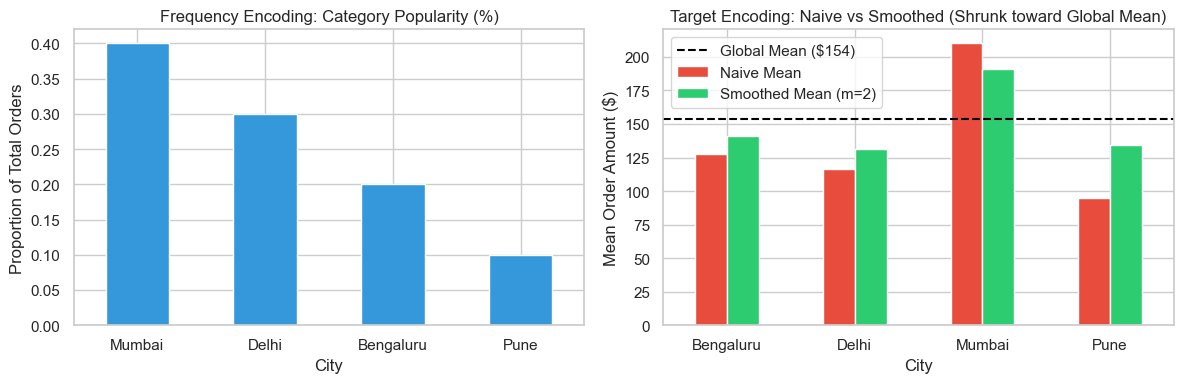

In [7]:
# 9. Visualizing Category Comparisons: Frequency vs Target vs Global Baseline
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot 1: Category Frequencies
city_frequency_map.plot(kind='bar', color='#3498db', ax=axes[0], rot=0)
axes[0].set_title('Frequency Encoding: Category Popularity (%)')
axes[0].set_ylabel('Proportion of Total Orders')
axes[0].set_xlabel('City')

# Plot 2: Naive vs Smoothed Target Mean vs Global Baseline
city_comp_df = pd.DataFrame({
    'Naive Mean': naive_means,
    'Smoothed Mean (m=2)': smoothed_means
})
city_comp_df.plot(kind='bar', ax=axes[1], color=['#e74c3c', '#2ecc71'], rot=0)
axes[1].axhline(global_mean, color='black', linestyle='--', linewidth=1.5, label=f'Global Mean (${global_mean:.0f})')
axes[1].set_title('Target Encoding: Naive vs Smoothed (Shrunk toward Global Mean)')
axes[1].set_ylabel('Mean Order Amount ($)')
axes[1].set_xlabel('City')
axes[1].legend()

plt.tight_layout()
plt.show()

## 10. Summary Comparison Matrix: One-Hot vs Ordinal vs Label vs Frequency vs Target Encoding

| Feature Dimension | One-Hot Encoding (OHE) | Ordinal Encoding | Label Encoding | Frequency (Count) Encoding | Target (Mean) Encoding |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Target ($y$) or Feature ($X$)?** | Feature ($X$) | Feature ($X$) | **Target ($y$) ONLY** | Feature ($X$) | Feature ($X$) |
| **Input Data Type** | Nominal | Ordinal (Inherent order) | Target Class Labels | Nominal (High Cardinality) | Nominal (High Cardinality) |
| **Output Columns** | $K$ (or $K-1$) | **1 Column** | **1 Column** | **1 Column** | **1 Column** |
| **Uses Target ($Y$)?** | ❌ No | ❌ No | ✅ Is the Target | ❌ No | **✅ Yes (Supervised)** |
| **Order Assumption** | None | Strict Natural Order | None (Arbitrary) | Popularity Order | Correlation with $Y$ |
| **Target Leakage Risk** | Zero | Zero | Zero | Zero | **⚠️ High (Needs OOF)** |
| **Best Use Cases** | Low Cardinality ($< 10$) | Education, Ratings, Sizes | Target classes in classification | High cardinality (Zip codes, IPs) | High cardinality (Brands, Cities) |
| **Implementation** | `OneHotEncoder`, `pd.get_dummies` | `OrdinalEncoder`, `df.map` | `LabelEncoder` | `df['col'].value_counts()` | `TargetEncoder` |

## 11. 🎯 Critical Interview Traps, Viva Hacks & Things to Learn

---

### ⚠️ Top 6 Interview Traps for Advanced Categorical Encoding

#### 🛑 Trap 1: `LabelEncoder` vs `OrdinalEncoder` for Features $X$
- **The Question:** *"Can I use `LabelEncoder` to encode my input features column `X['City']`?"*
- **The Disaster:** **NO!** `LabelEncoder` was designed solely for target arrays `y`. If you use it on input features $X$, it arbitrarily assigns integers alphabetically (`Chennai=0, Delhi=1, Mumbai=2`), which causes linear models, SVMs, and neural networks to assume Mumbai is twice as large as Delhi!
- **The Fix:** For input features $X$, always use `OrdinalEncoder` (for ranked features) or `OneHotEncoder` / `TargetEncoder` (for unranked features).

---

#### 🛑 Trap 2: The Scikit-Learn Alphabetical Ordering Trap (Ordinal)
- **The Question:** *"What happens if you run `OrdinalEncoder().fit_transform(df[['education']])` without specifying categories?"*
- **The Disaster:** Scikit-Learn sorts unique strings alphabetically:
  $$\text{'Bachelor'} \mapsto 0, \quad \text{'High School'} \mapsto 1, \quad \text{'Master'} \mapsto 2, \quad \text{'PhD'} \mapsto 3$$
  It mathematically asserts that a Bachelor's degree is **less educated** than a High School diploma!
- **The Fix:** ALWAYS pass explicit ordered nested lists: `categories=[['High School', 'Bachelor', 'Master', 'PhD']]`.

---

#### 🛑 Trap 3: The "Frequency Collision" Problem (Frequency)
- **The Question:** *"What is the primary failure mode of Frequency Encoding?"*
- **The True Flaw (Collision):** If two completely different categories (e.g. `'Kolkata'` and `'Chennai'`) happen to appear the **exact same number of times** (e.g. 50 orders each), both get mapped to the exact same frequency score (`0.05`). The model cannot differentiate between Kolkata and Chennai!
- **The Fix:** Combine Frequency Encoding with Target Encoding or Top-N One-Hot Encoding.

---

#### 🛑 Trap 4: Catastrophic Target Leakage (Encoding Before Train/Test Split)
- **The Question:** *"Can I apply target encoding directly to my entire dataset before calling `train_test_split()`?"*
- **The Disaster:** **NO! Never!** If you compute category means across the entire dataset, you are directly baking the test set's ground-truth target values into the training features. Your training validation scores will look 99% accurate, but the model will crash and burn in production.
- **The Fix:** Always split first:
  ```python
  encoder = TargetEncoder(smooth="auto")
  X_train_encoded = encoder.fit_transform(X_train, y_train)
  X_test_encoded = encoder.transform(X_test)  # Transform ONLY, NEVER fit on test!
  ```

---

#### 🛑 Trap 5: Overfitting on Rare Categories & Singletons
- **The Question:** *"What happens if a category appears only once in the dataset?"*
- **The Disaster:** If a city appears once with $y=1,000,000$, naive mean encoding maps that city to $1,000,000$. The model learns that this category guarantees a million dollars, leading to extreme variance and overfitting.
- **The Fix:** Use Empirical Bayes Smoothing / M-estimate shrinkage:
  $$S_c = \frac{n_c \cdot \bar{y}_c + m \cdot \bar{y}_{\text{global}}}{n_c + m}$$

---

#### 🛑 Trap 6: Self-Prediction in Training Data (Why Out-of-Fold is Mandatory)
- **The Question:** *"Why does modern Scikit-Learn `TargetEncoder` require cross-validation (`cv=5`) during `fit_transform()`?"*
- **The Insight:** If a row's own target value is used to calculate its feature representation, the model simply memorizes the target! Out-of-fold (OOF) cross-fitting ensures that **row $i$'s encoding is calculated using only the other folds**, preventing any row from learning from its own label.

---

### 🧠 Golden Rules of Thumb (Mental Checklist)
1. **Target variable ($y$) $\to$ use `LabelEncoder()`**.
2. **Feature with true hierarchy $\to$ use `OrdinalEncoder(categories=[[...]])`**.
3. **Nominal feature with $< 10$ unique values $\to$ use `OneHotEncoder(drop='first')`**.
4. **Nominal feature with high cardinality ($> 20$ values) $\to$ use `TargetEncoder(smooth='auto')` or Frequency Encoding**.
5. **Tree models (LightGBM, CatBoost)** prefer integer or native categorical handling over wide one-hot matrices.